---
title: "L4-03 · Confounders, mediators, and colliders"
short_title: "Confounders, mediators, and colliders"
subtitle: "The same act, adding a variable to a regression or stratifying on it, removes bias when the variable is a confounder, removes part of the effect when it is a mediator, and creates bias when it is a collider; the graph, not the data, tells you which."
description: "Choose adjustment variables by their role in the causal graph relative to a treatment and an outcome, and compute what adjusting for a confounder, a mediator or a collider does to an estimate."
tags: [level-4, coursebook]
---

(lesson-l4-03)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 100 minutes  
**Big idea.** The same act, adding a variable to a regression or stratifying on it, removes bias when the variable is a confounder, removes part of the effect when it is a mediator, and creates bias when it is a collider; the graph, not the data, tells you which.  
**Before this lesson.** [L4-02](#lesson-l4-02)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Label each variable of a causal graph as a confounder, mediator or collider relative to a stated treatment, outcome and path.
- Derive the omitted-variable formula $\beta + \gamma\,\mathrm{Cov}(X, Z)/\mathrm{Var}(X)$ and use it to explain a reversed slope.
- Compute the total and direct effects in a linear mediation model and show what regression on a mediator estimates.
- Prove that selecting on a sum of independent variables induces a negative correlation and compute it.

## Why this matters

"Control for everything you can measure" sounds like caution. It is not. Take a study of a treatment $X$ and an outcome $Y$ with three extra variables: $Z$ measured before treatment, $M$ measured between treatment and outcome, and $C$ measured afterward. In the linear model of this lesson the true total effect is 4. Regressing $Y$ on $X$ alone gives 5. Adding $Z$ gives 4, correct. Adding $Z$ and $M$ gives 1. Adding all three gives 0. Every one of these numbers is an exact population value; none is noise.

The three extra variables play three different roles. $Z$ is a confounder: adjusting for it removes bias. $M$ is a mediator: adjusting for it removes part of the very effect you want. $C$ is a collider: adjusting for it creates bias out of nothing. [L4-02](#lesson-l4-02) gave the path rules; this lesson applies them to the practical question of what to adjust for, with formulas for how much each mistake costs [@hernan; @pearlcausality].

:::{dropdown} Key terms

**Confounder**
: A variable on an open noncausal (backdoor) path between treatment and outcome, typically a common cause of both.

**Mediator**
: A variable on a directed path from treatment to outcome, through which part of the effect flows.

**Collider**
: A node with two arrowheads on a path; conditioning on it, or on its descendant, opens the path.

**Total effect**
: The change in $\mathbb{E}[Y \mid do(X = x)]$ per unit change in $x$, through all directed paths.

**Controlled direct effect**
: The effect of $X$ on $Y$ with the mediator held fixed by intervention; in a linear model, the coefficient on the direct arrow.

**Selection bias**
: Bias from analyzing only units that pass a selection rule which depends on the variables being studied; often a collider at the selection node.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_03 as _lessonfigs

## Roles are relative to a question

Fix a treatment $X$ and an outcome $Y$. Every other variable gets a role from the paths it sits on between $X$ and $Y$. A path that starts with an arrow into $X$, as in $X \leftarrow Z \to Y$, is a **backdoor path**: it carries association but not effect. A path whose arrows all point from $X$ toward $Y$ is **causal**.

:::{prf:definition} Confounder, mediator, collider
:label: def-l4-03-roles
Relative to $X$, $Y$ and a path $p$ between them: a node $W$ on $p$ is a **mediator** if $p$ is a directed path $X \to \cdots \to W \to \cdots \to Y$; a **collider** if both edges of $p$ at $W$ point into $W$; and a **confounding** node if $p$ is a backdoor path and $W$ is a noncollider on it, so that conditioning on $W$ blocks $p$. A variable is called a confounder of the effect of $X$ on $Y$ when it lies, as a noncollider, on an open backdoor path [@hernan; @pearlcausality].
:::

```{mermaid}
graph LR
  Z((Z)) --> X((X))
  Z --> Y((Y))
  X --> M((M))
  M --> Y
  X --> Y
  X --> C((C))
  Y --> C
```

*The lesson's combined graph. Relative to the effect of $X$ on $Y$: $Z$ is a confounder (on the backdoor path $X \leftarrow Z \to Y$), $M$ is a mediator (on $X \to M \to Y$), and $C$ is a collider (on $X \to C \leftarrow Y$). The linear coefficients are $Z \to X$: 1, $X \to M$: 1.5, $M \to Y$: 2, $X \to Y$: 1, $Z \to Y$: 2, and 1 for both arrows into $C$.*

:::{important} A practical rule, made precise in L4-04
To estimate a total effect, adjust for variables that block every backdoor path, and never adjust for a descendant of the treatment (mediators, colliders such as $C$, and their descendants). [L4-04](#lesson-l4-04) proves that this backdoor criterion is sufficient. Being measured before treatment is not enough on its own: a pre-treatment collider exists (see the remark on M-bias below).
:::

## Confounders: a slope that reverses

Let $Z$ be a fair coin, $X := 2Z + N_X$ and $Y := 3Z - 0.5X + 0.5N_Y$ with standard normal noises. The causal effect of $X$ on $Y$ is $-0.5$. But $Z$ raises both $X$ and $Y$, so in pooled data high $X$ comes with high $Y$.

:::{prf:proposition} Omitted-variable formula
:label: prop-l4-03-ovb
Suppose $Y = \beta X + \gamma Z + N_Y$ with $\mathbb{E}[N_Y] = 0$ and $N_Y$ uncorrelated with $(X, Z)$. Then the population slope of the regression of $Y$ on $X$ alone is
:::

$$
\beta_{\text{pooled}} = \frac{\mathrm{Cov}(X, Y)}{\mathrm{Var}(X)} = \beta + \gamma\,\frac{\mathrm{Cov}(X, Z)}{\mathrm{Var}(X)}
$$ (eq-l4-03-ovb)

:::{prf:proof}
$\mathrm{Cov}(X, Y) = \beta\,\mathrm{Var}(X) + \gamma\,\mathrm{Cov}(X, Z) + \mathrm{Cov}(X, N_Y)$, and the last term is zero. Divide by $\mathrm{Var}(X)$. Regressing on both $X$ and $Z$ instead returns $(\beta, \gamma)$, because the normal equations are solved by the true coefficients when $N_Y$ is uncorrelated with the regressors.
:::

Here $\mathrm{Var}(Z) = 1/4$, $\mathrm{Cov}(X, Z) = 2 \cdot 1/4 = 0.5$ and $\mathrm{Var}(X) = 4 \cdot 1/4 + 1 = 2$, so [](#eq-l4-03-ovb) gives $\beta_{\text{pooled}} = -0.5 + 3 \cdot 0.5/2 = 0.25$. The pooled slope has the wrong sign. Within each stratum of $Z$ the slope is $-0.5$, the causal effect. This is the reversal of [L2-06](#lesson-l2-06), now with a formula for its size.

:::{figure} ../../_static/animations/l4_03_confounder_strata.mp4
:alt: A scatter plot whose pooled regression line rises with slope 0.25; when points are colored by Z, each group shows a falling line with slope -0.5.
:width: 100%

Pooled, the slope is $0.25$; within each stratum of the confounder, it is $-0.5$. The omitted-variable formula accounts for the whole gap.
:::

:::{dropdown} What the animation shows
A scatter plot shows 160 sampled points from the model $Z \in \{0, 1\}$ with probability one half each, $X := 2Z + N_X$, $Y := 3Z - 0.5X + 0.5N_Y$; a small graph beside it has arrows $Z \to X$ (coefficient 2), $Z \to Y$ (coefficient 3) and $X \to Y$ (coefficient $-0.5$). First all points are grey and the population regression line of $Y$ on $X$ is drawn: pooled slope $0.25$, rising. Then the points are colored by $Z$: blue for $Z = 0$ (lower left) and orange for $Z = 1$ (upper right). Inside each color a line with slope $-0.5$ is drawn, falling, and the pooled line fades. A derivation on the right explains the gap: $\beta_{\text{pooled}} = \beta + \gamma\,\mathrm{Cov}(X, Z)/\mathrm{Var}(X)$, which becomes $-0.5 + 3 \cdot 0.5/2$ and then $0.25$. The last line says that adjusting for $Z$ recovers $-0.5$.
:::

## Mediators: adjusting removes part of the effect

Now let $M := 1.5X + N_M$ and $Y := X + 2M + N_Y$, with $X$, $N_M$, $N_Y$ independent. Substituting the first assignment into the second gives $Y = X + 2(1.5X + N_M) + N_Y = 4X + 2N_M + N_Y$, so $\mathbb{E}[Y \mid do(X = x)] = 4x$: the **total effect** is 4, of which 1 travels along $X \to Y$ and $1.5 \times 2 = 3$ along $X \to M \to Y$.

:::{prf:proposition} What regression on a mediator estimates
:label: prop-l4-03-mediator
In the linear model $M := bX + N_M$, $Y := dX + eM + N_Y$ with $X$, $N_M$, $N_Y$ independent, the total effect of $X$ on $Y$ is $d + be$, and the population regression of $Y$ on $(X, M)$ has coefficient $d$ on $X$: the controlled direct effect, not the total effect.
:::

:::{prf:proof}
Substitution gives $Y = (d + be)X + eN_M + N_Y$, and under $do(X = x)$ the same substitution holds with $X = x$, so $\mathbb{E}[Y \mid do(x)] = (d + be)x$. For the regression, $Y = dX + eM + N_Y$ with $N_Y$ independent of $(X, M)$ (because $M$ is a function of $X$ and $N_M$), so $\mathbb{E}[Y \mid X, M] = dX + eM$ and the coefficients are $(d, e)$.
:::

:::{figure} ../../_static/animations/l4_03_mediator_adjust.mp4
:alt: A graph X to M to Y with a direct arrow X to Y; a stacked bar of height 4 split into direct 1 and indirect 3; adjusting for M drains the indirect part.
:width: 100%

The total effect $4X + 2N_M + N_Y$ splits into a direct part 1 and an indirect part 3. Holding $M$ fixed in the regression leaves only the direct part.
:::

:::{dropdown} What the animation shows
A graph has $X \to M$ with coefficient 1.5, $M \to Y$ with coefficient 2, and $X \to Y$ with coefficient 1. The assignments $M := 1.5X + N_M$ and $Y := X + 2M + N_Y$ are written, and substitution turns $Y = X + 2(1.5X + N_M) + N_Y$ into $Y = 4X + 2N_M + N_Y$: the total effect of $X$ on $Y$ is 4. A stacked bar shows this 4 as a purple direct part of height 1 and an orange indirect part of height $1.5 \times 2 = 3$, labeled regress $Y$ on $X$. Then $M$ turns grey (adjusted for), the arrows through $M$ fade, and the orange part drains away, leaving the purple bar of height 1, labeled regress $Y$ on $X$ and $M$. The formula $\mathbb{E}[Y \mid X, M] = 1 \cdot X + 2M$ appears with the notes: coefficient of $X$ is 1, the direct effect; valid only if nothing else links $M$ and $Y$.
:::

:::{warning} The direct effect needs its own assumptions
The proof used that nothing else links $M$ and $Y$. If an unmeasured $U$ affects both ($M \leftarrow U \to Y$), then $M$ is a collider on $X \to M \leftarrow U \to Y$, and conditioning on $M$ opens that path: the coefficient on $X$ is then biased even for the direct effect (the last challenge exercise computes how much). Mediation analysis is a subject of its own [@hernan; @pearlcausality].
:::

## Colliders: selection creates association

Let $A$ and $B$ be independent fair coins, and keep a record only when $C = \max(A, B) = 1$. The kept pairs are $01$, $10$ and $11$, equally likely. Then $P(A = 1 \mid C = 1) = 2/3$ for each coin, but $P(A = 1, B = 1 \mid C = 1) = 1/3 \ne (2/3)^2 = 4/9$. Within the kept records the coins are dependent: learning that one is 0 forces the other to be 1. This is **Berkson's paradox**; the selection node $C$ is a collider on $A \to C \leftarrow B$.

:::{prf:proposition} Selection on a sum
:label: prop-l4-03-sum
Let $A, B$ be independent $N(0, 1)$ and keep only units with $S = A + B > t$. Then, among kept units, $\operatorname{corr}(A, B) = \frac{v - 2}{v + 2}$ where $v = \mathrm{Var}(S \mid S > t)$. Since $v < 2$, the correlation is negative for every $t$; at $t = 0$ it equals $-1/(\pi - 1) \approx -0.467$.
:::

:::{prf:proof}
Let $D = A - B$. The pair $(S, D)$ is jointly normal with $\mathrm{Cov}(S, D) = \mathrm{Var}(A) - \mathrm{Var}(B) = 0$, so $S$ and $D$ are independent, each $N(0, 2)$. Selection depends only on $S$, so after selection $D$ is still $N(0, 2)$ and independent of $S$. Write $A = (S + D)/2$ and $B = (S - D)/2$. Then $\mathrm{Cov}(A, B \mid S > t) = (v - 2)/4$ and $\mathrm{Var}(A \mid S > t) = \mathrm{Var}(B \mid S > t) = (v + 2)/4$, which gives the ratio. Truncating a normal distribution strictly reduces its variance, so $v < 2$. At $t = 0$, $S \mid S > 0$ is half-normal with $v = 2(1 - 2/\pi)$, and $(v - 2)/(v + 2) = (-4/\pi)/(4 - 4/\pi) = -1/(\pi - 1)$.
:::

:::{figure} ../../_static/animations/l4_03_collider_selection.mp4
:alt: Independent points A, B; a line A + B = t sweeps across and points below it turn grey; a live graph shows the correlation among kept points falling below zero.
:width: 100%

Keep only $A + B > t$. The stricter the selection, the more negative the correlation among the kept units, although $A$ and $B$ are independent in the population.
:::

:::{dropdown} What the animation shows
A scatter of 300 points $(A, B)$ drawn independently from standard normals, all red at first. A line $A + B = t$ sweeps from the lower left to the upper right as $t$ goes from $-3.5$ to $1.5$; points below the line turn grey (not kept) and points above stay red (kept). On the right, a graph of the population correlation $\operatorname{corr}(A, B \mid A + B > t)$ against $t$ is traced live, starting near 0 and falling steadily, with a readout of $t$ and the correlation (about $-0.30$ at $t = -1$ and $-0.62$ at $t = 1$). The threshold then returns to $t = 0$, where the value $-1/(\pi - 1) \approx -0.467$ is marked and boxed. The formula $\operatorname{corr} = \frac{v - 2}{v + 2}$ with $v = \mathrm{Var}(A + B \mid A + B > t)$ is shown at the bottom.
:::


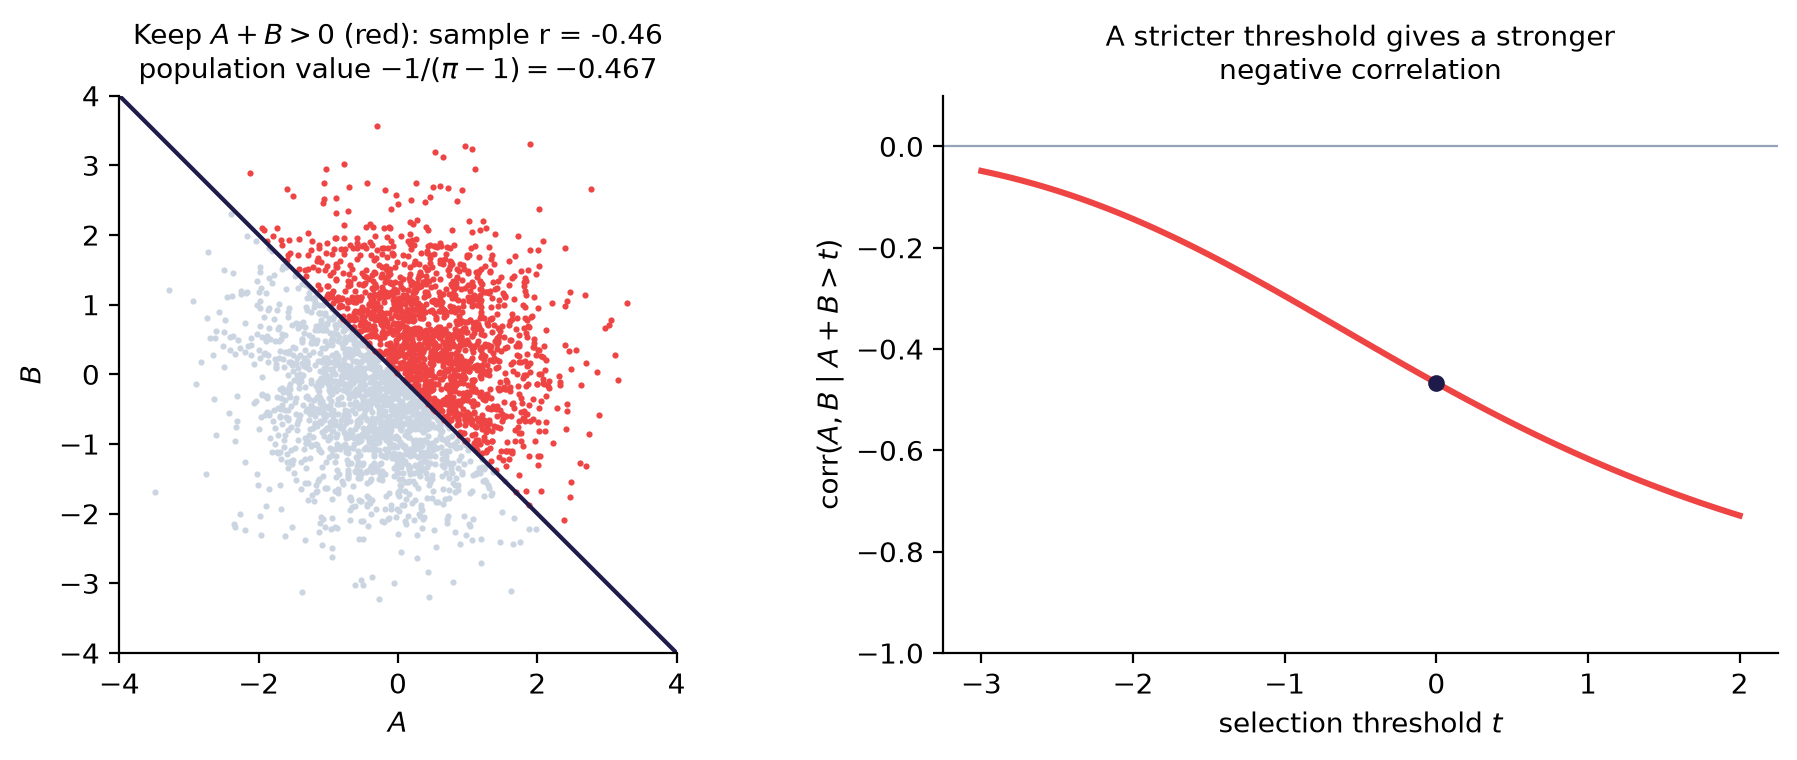

In [2]:
_show_mpl(_lessonfigs.berkson_figure())

*Left: 3000 independent pairs, with the kept ones ($A + B > 0$) in red; the sample correlation among kept pairs is close to the population value $-1/(\pi - 1)$. Right: the population correlation among kept pairs as a function of the threshold $t$, from Proposition [](#prop-l4-03-sum).*

:::{prf:remark} M-bias: a collider measured before treatment
In $X \leftarrow U_1 \to W \leftarrow U_2 \to Y$ with $U_1, U_2$ unmeasured, the pre-treatment variable $W$ is a collider. The backdoor path is blocked as long as $W$ is left alone; adjusting for $W$ opens it. If $W$ also affects $X$ or $Y$ directly, it can be both a collider and a confounder on different paths, and no adjustment by observed variables may suffice. Roles belong to paths, not to variables [@hernan; @pearlcausality].
:::

## All three at once


In [3]:
_show(_lessonfigs.adjustment_explorer())

**Explore.** Choose an adjustment set for the combined model with the buttons (none, $\{Z\}$, $\{Z, M\}$, $\{Z, C\}$, $\{Z, M, C\}$); the bars for $\{M\}$ and $\{C\}$ are shown for comparison. Each bar shows the exact population coefficient of $X$ when $Y$ is regressed on $X$ and the chosen variables; the dashed lines mark the total effect 4 and the direct effect 1.

:::{dropdown} What the figure shows
The first panel shows the combined graph with the adjusted variables in grey. Five buttons choose the adjustment set: none, $\{Z\}$, $\{Z, M\}$, $\{Z, C\}$ and $\{Z, M, C\}$. The second panel shows one labeled bar for each of seven adjustment sets, with the chosen one highlighted. The exact coefficients are: none 5, $\{Z\}$ 4, $\{Z, M\}$ 1, $\{Z, C\}$ $-0.17$, $\{M\}$ 2, $\{C\}$ $-0.25$, and $\{Z, M, C\}$ 0. Only $\{Z\}$ hits the total effect, and only $\{Z, M\}$ hits the direct effect.
:::

Simulate the combined model and run the seven regressions. With 200 000 samples the coefficients match the exact values in the interactive to about two decimals.


In [4]:
import itertools
import numpy as np

# Combined linear SCM: Z confounder, M mediator, C collider (independent standard normal noises)
rng = np.random.default_rng(42)
n = 200_000
Z = rng.normal(size=n)
X = Z + rng.normal(size=n)
M = 1.5 * X + rng.normal(size=n)
Y = X + 2 * M + 2 * Z + rng.normal(size=n)
C = X + Y + rng.normal(size=n)
data = {"Z": Z, "M": M, "C": C}

def coef_of_x(adjust):
    cols = [np.ones(n), X] + [data[v] for v in adjust]
    beta, *_ = np.linalg.lstsq(np.column_stack(cols), Y, rcond=None)
    return beta[1]

print("true total effect 4, direct effect 1")
for k in range(4):
    for adj in itertools.combinations(["Z", "M", "C"], k):
        name = ", ".join(adj) or "nothing"
        print(f"adjust for {name:8s}  coefficient of X = {coef_of_x(adj):6.3f}")

true total effect 4, direct effect 1
adjust for nothing   coefficient of X =  5.004
adjust for Z         coefficient of X =  3.998
adjust for M         coefficient of X =  1.992
adjust for C         coefficient of X = -0.254
adjust for Z, M      coefficient of X =  0.999
adjust for Z, C      coefficient of X = -0.170
adjust for M, C      coefficient of X = -0.252
adjust for Z, M, C   coefficient of X = -0.000


The two collider examples: exact fractions for the coins, and a Monte Carlo check of Proposition [](#prop-l4-03-sum) at $t = 0$.


In [5]:
from fractions import Fraction
import math

# Berkson with coins: A, B fair and independent, keep a record when C = max(A, B) = 1
kept = [(a, b) for a in (0, 1) for b in (0, 1) if max(a, b) == 1]
pA = Fraction(sum(a for a, b in kept), len(kept))
pAB = Fraction(sum(a * b for a, b in kept), len(kept))
print("P(A=1 | C=1) =", pA, "  P(A=1, B=1 | C=1) =", pAB, "  product of marginals =", pA * pA)

# Selection on a sum: A, B ~ N(0,1) independent, keep A + B > 0
A_, B_ = rng.normal(size=(2, 400_000))
keep = A_ + B_ > 0
print("sample corr among kept:", round(np.corrcoef(A_[keep], B_[keep])[0, 1], 4))
v = 2 * (1 - 2 / math.pi)                       # Var(A + B | A + B > 0): half-normal with variance 2
print("formula (v - 2)/(v + 2) =", round((v - 2) / (v + 2), 4), "  -1/(pi - 1) =", round(-1 / (math.pi - 1), 4))

P(A=1 | C=1) = 2/3   P(A=1, B=1 | C=1) = 1/3   product of marginals = 4/9
sample corr among kept: -0.4682
formula (v - 2)/(v + 2) = -0.4669   -1/(pi - 1) = -0.4669


## Worked example

:::{admonition} Reading roles and predicting estimates in the combined model
:class: tip

In the combined graph ($Z \to X$, $Z \to Y$, $X \to M \to Y$, $X \to Y$, $X \to C \leftarrow Y$) with the stated coefficients, which adjustment set estimates the total effect of $X$ on $Y$, and what does regressing on $X$ alone give?

1. List the paths from $X$ to $Y$: causal $X \to Y$ and $X \to M \to Y$; backdoor $X \leftarrow Z \to Y$; and $X \to C \leftarrow Y$, which is blocked at the collider $C$ unless $C$ is conditioned on.
2. The total effect is the sum over causal paths: $1 + 1.5 \cdot 2 = 4$. To estimate it, block the backdoor path with $Z$, leave $M$ (a mediator) and $C$ (a collider and descendant of $X$) alone: adjustment set $\{Z\}$.
3. Regressing on $X$ alone leaves the backdoor open. With $Y = 4X + 2Z + (\text{noise uncorrelated with } X)$ after substituting $M$, formula [](#eq-l4-03-ovb) gives $4 + 2\,\mathrm{Cov}(X, Z)/\mathrm{Var}(X) = 4 + 2 \cdot 1/2 = 5$.
4. Adding $M$ to $\{Z\}$ blocks the indirect path and leaves the direct coefficient 1 (Proposition [](#prop-l4-03-mediator)); adding $C$ opens $X \to C \leftarrow Y$ and drives the estimate below zero.

**Result.** $\{Z\}$ gives the total effect 4; no adjustment gives 5; $\{Z, M\}$ gives the direct effect 1; sets containing $C$ give values unrelated to either effect.
:::

## Exercises

**1. (Core)** With independent fair coins $A$, $B$ and the inclusion rule $C = \max(A, B) = 1$, calculate $P(B = 1 \mid A = 0, C = 1)$ and $P(B = 1 \mid A = 1, C = 1)$.

:::{dropdown} Solution
If $A = 0$ and the record is kept, $B$ must be 1, so the first probability is 1. If $A = 1$, the record is kept whatever $B$ is, and both values stay equally likely, so the second probability is $1/2$. Since these differ, $A$ and $B$ are dependent given $C = 1$.
:::

**2. (Core)** In the combined graph, give the role of $Z$, $M$ and $C$ relative to the effect of $X$ on $Y$, and say which of them should be adjusted for to estimate the total effect.

:::{dropdown} Solution
$Z$ is a confounder (noncollider on the backdoor path $X \leftarrow Z \to Y$); $M$ is a mediator (on the causal path $X \to M \to Y$); $C$ is a collider on $X \to C \leftarrow Y$ and a descendant of $X$. Adjust for $Z$ only.
:::

**3. (Stretch)** In the mediation model take $b = 0.5$, $e = -2$, $d = 1$. Compute the total effect and the coefficient of $X$ when $Y$ is regressed on $X$ and $M$. What would an analyst conclude from each number?

:::{dropdown} Solution
Total effect $d + be = 1 + 0.5 \cdot (-2) = 0$. The regression on $(X, M)$ gives $d = 1$. An analyst who adjusts for $M$ would report a positive effect of $X$, while setting $X$ actually leaves the mean of $Y$ unchanged: the direct and indirect paths cancel. Both numbers are correct answers to different questions.
:::

**4. (Stretch)** Let $Z \sim N(0, 1)$, $X := Z + N_X$, $Y := \beta X + 2Z + N_Y$ with independent standard normal noises. Find the slope of the regression of $Y$ on $X$ alone.

:::{dropdown} Solution
$\mathrm{Cov}(X, Z) = 1$ and $\mathrm{Var}(X) = 2$, so formula [](#eq-l4-03-ovb) gives $\beta + 2 \cdot 1/2 = \beta + 1$. The bias is $+1$ whatever $\beta$ is.
:::

**5. (Challenge)** Use Proposition [](#prop-l4-03-sum) and the half-normal variance to show that $\operatorname{corr}(A, B \mid A + B > 0) = -1/(\pi - 1)$, and explain why the correlation tends to 0 as $t \to -\infty$.

:::{dropdown} Solution
For $S \sim N(0, \sigma^2)$, $\mathbb{E}[S \mid S > 0] = \sigma\sqrt{2/\pi}$ and $\mathbb{E}[S^2 \mid S > 0] = \sigma^2$, so $\mathrm{Var}(S \mid S > 0) = \sigma^2(1 - 2/\pi)$. With $\sigma^2 = 2$, $v = 2 - 4/\pi$, and $(v - 2)/(v + 2) = (-4/\pi)/(4 - 4/\pi) = -1/(\pi - 1) \approx -0.467$. As $t \to -\infty$ almost every unit is kept, so $v \to 2$ and the correlation $(v - 2)/(v + 2) \to 0$: no selection, no induced correlation.
:::

**6. (Challenge)** Mediator-outcome confounding. Let $X, U, N_M, N_Y$ be independent standard normals, $M := X + U + N_M$ and $Y := X + M + U + N_Y$. The direct effect of $X$ is 1. Find the population coefficient of $X$ when $Y$ is regressed on $X$ and $M$, and explain the bias with a path.

:::{dropdown} Solution
Given $X$ and $M$, the only unknown in $Y$ is $U + N_Y$. Since $M - X = U + N_M$ with $\mathrm{Var}(U) = \mathrm{Var}(N_M) = 1$, the best linear predictor is $\mathbb{E}[U \mid X, M] = (M - X)/2$, and $N_Y$ predicts to 0. So $\mathbb{E}[Y \mid X, M] = X + M + (M - X)/2 = 0.5X + 1.5M$, and the coefficient on $X$ is $0.5$, not 1. Conditioning on $M$ opens $X \to M \leftarrow U \to Y$, where $M$ is a collider.
:::

## Check your understanding

**1. Which adjustment can create a new noncausal association between treatment and outcome?**

- **A.** Recording the treatment definition
- **B.** Conditioning on a collider such as $C$ in $X \to C \leftarrow Y$
- **C.** Conditioning on a common cause of $X$ and $Y$
- **D.** Collecting more independent samples

:::{dropdown} Show the answer
**B. Conditioning on a collider such as $C$ in $X \to C \leftarrow Y$**

A collider blocks its path until it, or a descendant, is conditioned on. Conditioning opens the path and creates association even when its causes were independent.
:::

**2. In $M := 1.5X + N_M$, $Y := X + 2M + N_Y$, what is the coefficient of $X$ when $Y$ is regressed on both $X$ and $M$?**

- **A.** 4
- **B.** 3
- **C.** 1
- **D.** 0

:::{dropdown} Show the answer
**C. 1**

Holding $M$ fixed removes the indirect path, leaving the direct coefficient 1. The total effect is 4, and 3 is the indirect part.
:::

**3. Pooled data show slope $0.25$; within each level of the only confounder $Z$ the slope is $-0.5$. Which number estimates the causal effect of $X$ on $Y$?**

- **A.** $0.25$, the pooled slope
- **B.** Neither can be causal
- **C.** Their average
- **D.** $-0.5$, the within-stratum slope

:::{dropdown} Show the answer
**D. $-0.5$, the within-stratum slope**

Stratifying on the confounder blocks the backdoor path $X \leftarrow Z \to Y$. The pooled slope adds the bias $\gamma\,\mathrm{Cov}(X, Z)/\mathrm{Var}(X) = 0.75$.
:::

**4. In the graph $A \to C \to D$ with $B \to C$, are $A$ and $B$ d-separated given $\{D\}$?** *(Review of [L4-02](#lesson-l4-02))*

- **A.** No, because $A$ causes $B$
- **B.** Yes, because $C$ is a collider
- **C.** Yes, because $D$ is not on the path
- **D.** No, because $D$ is a descendant of the collider $C$

:::{dropdown} Show the answer
**D. No, because $D$ is a descendant of the collider $C$**

The only path is $A \to C \leftarrow B$ with collider $C$. Conditioning on its descendant $D$ opens it, so $A$ and $B$ are d-connected given $\{D\}$.
:::

## Common misconceptions

- **"Adjusting for more variables is always safer."** In the combined model, adding $M$ to the correct set $\{Z\}$ moves the estimate from 4 to 1, and adding $C$ moves it to 0. Each added variable must earn its place by its role in the graph.
- **"Any variable measured before treatment is safe to adjust for."** Timing rules out mediators and descendants of treatment, but not colliders: in the M-bias graph a pre-treatment variable is a collider and adjusting for it creates bias.
- **"A correlation found among selected cases must reflect a real link."** Selecting on a common effect induces correlation between independent causes: $-1/(\pi - 1) \approx -0.467$ for selection on $A + B > 0$, with no link between $A$ and $B$ at all.

:::{caution} Scope and limits
All numbers here come from fully specified linear-Gaussian or binary models, so regression coefficients equal the causal quantities exactly when the assumptions hold. With nonlinear models, effect heterogeneity or measurement error, adjusting for the right set still removes confounding but the regression coefficient may no longer equal the average effect; [L4-04](#lesson-l4-04) uses standardization instead. Roles are assigned relative to an assumed graph; if the graph omits an unmeasured common cause, a variable can be a confounder and a collider at once, and no adjustment set from the observed variables may exist.
:::

:::{seealso} Where this leads
The roles defined here become a criterion in [L4-04](#lesson-l4-04): a set satisfies the backdoor criterion if it blocks every backdoor path and contains no descendant of the treatment. [L4-05](#lesson-l4-05) shows that a mediator can rescue identification when the confounder is unmeasured, and [L4-10](#lesson-l4-10) returns to selection when data are transported between populations. Collider bias reappears in Level 6, where post-selection in quantum experiments raises the same question of what conditioning creates.
:::

:::{dropdown} For instructors

**Why this lesson.** Students and many practitioners adjust for every available covariate. Showing four exact numbers (5, 4, 1, 0) from one model, each produced by a defensible-looking regression, makes the case that the graph must come before the regression [@hernan; @pearlcausality; @seeing].

**Teaching notes.**

- Open with the four regression results of the combined model and ask the class to rank them before revealing which equals the total effect.
- Link the confounder animation to the reversal lesson [L2-06](#lesson-l2-06): the omitted-variable formula is the quantitative version of that story.
- Run the Berkson coin example physically: students flip two coins, discard the trials with two tails, and tabulate the rest. The dependence is visible after about 40 trials.
- Stress that the mediator result answers a different question (direct effect) and needs an extra assumption (no mediator-outcome confounding).

**Assessment.** The core exercises test role labeling and Berkson's rule; the stretch exercise on cancelling paths tests the difference between total and direct effects; the last challenge exercise tests whether students can see a collider hidden inside a mediation analysis.

**Going further.** Have students write a function that, given a DAG, a treatment and an outcome, lists every adjustment set of observed variables that blocks all backdoor paths without descendants of the treatment, and test it on the M-bias and butterfly graphs. Hernán and Robins discuss selection bias as collider stratification in detail [@hernan], and DoWhy implements this kind of check [@dowhy].

:::

## References

This lesson draws on [@hernan; @pearlcausality; @pearl; @seeing; @bradyneal; @dowhy].

**Further reading.**

- [@hernan]: The chapters on confounding and on selection bias treat both in the language of graphs.
- [@dowhy]: A library that identifies valid adjustment sets from a stated graph before estimating.

**Next:** [L4-04 · Backdoor adjustment](#lesson-l4-04)
